In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# Support running the notebook from either project root
# or the evidence_map directory.
if not (PROJECT_ROOT / "dataset" / "volumes").exists():
    PROJECT_ROOT = PROJECT_ROOT.parents[2]

EVIDENCE_MAP_DIR = PROJECT_ROOT / "src" / "evidence_map"

sys.path.insert(0, str(EVIDENCE_MAP_DIR))

from retrieve_examples import retrieve_for_patient

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "evidence_map"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)

Project root: d:\
Output directory: d:\outputs\evidence_map


In [3]:
import sys
from pathlib import Path

# Set the exact project directory
PROJECT_ROOT = Path(r"D:\PS07_CT2MRI")

# Verify the project directory
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")

EVIDENCE_MAP_DIR = PROJECT_ROOT / "src" / "evidence_map"

sys.path.insert(0, str(EVIDENCE_MAP_DIR))

from retrieve_examples import retrieve_for_patient

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "evidence_map"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("EvidenceMap folder:", EVIDENCE_MAP_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: D:\PS07_CT2MRI
EvidenceMap folder: D:\PS07_CT2MRI\src\evidence_map
Output directory: D:\PS07_CT2MRI\outputs\evidence_map


In [4]:
# ============================================================
# RUN EVIDENCEMAP RETRIEVAL
# ============================================================

PATIENT_ID = "P8947"

print("Retrieving evidence for:", PATIENT_ID)

result = retrieve_for_patient(
    patient_id=PATIENT_ID,
    top_k=3
)

query_ct = result["query_patch"]

evidence = result["evidence"]

retrieved_ct = evidence["ct_patches"]
retrieved_mr = evidence["mr_patches"]
matches = evidence["matches"]

print("\nQuery CT shape:", query_ct.shape)
print("Retrieved CT shape:", retrieved_ct.shape)
print("Retrieved MRI shape:", retrieved_mr.shape)

print("\nRetrieved references:")

for match in matches:
    print(
        f"Rank {match['rank']} | "
        f"Patient: {match['patient_id']} | "
        f"Similarity: {match['similarity']:.4f}"
    )

Retrieving evidence for: P8947

Query CT shape: (32, 32)
Retrieved CT shape: (3, 32, 32)
Retrieved MRI shape: (3, 32, 32)

Retrieved references:
Rank 1 | Patient: P1375 | Similarity: 0.8759
Rank 2 | Patient: P8490 | Similarity: 0.8500
Rank 3 | Patient: P2161 | Similarity: 0.8461


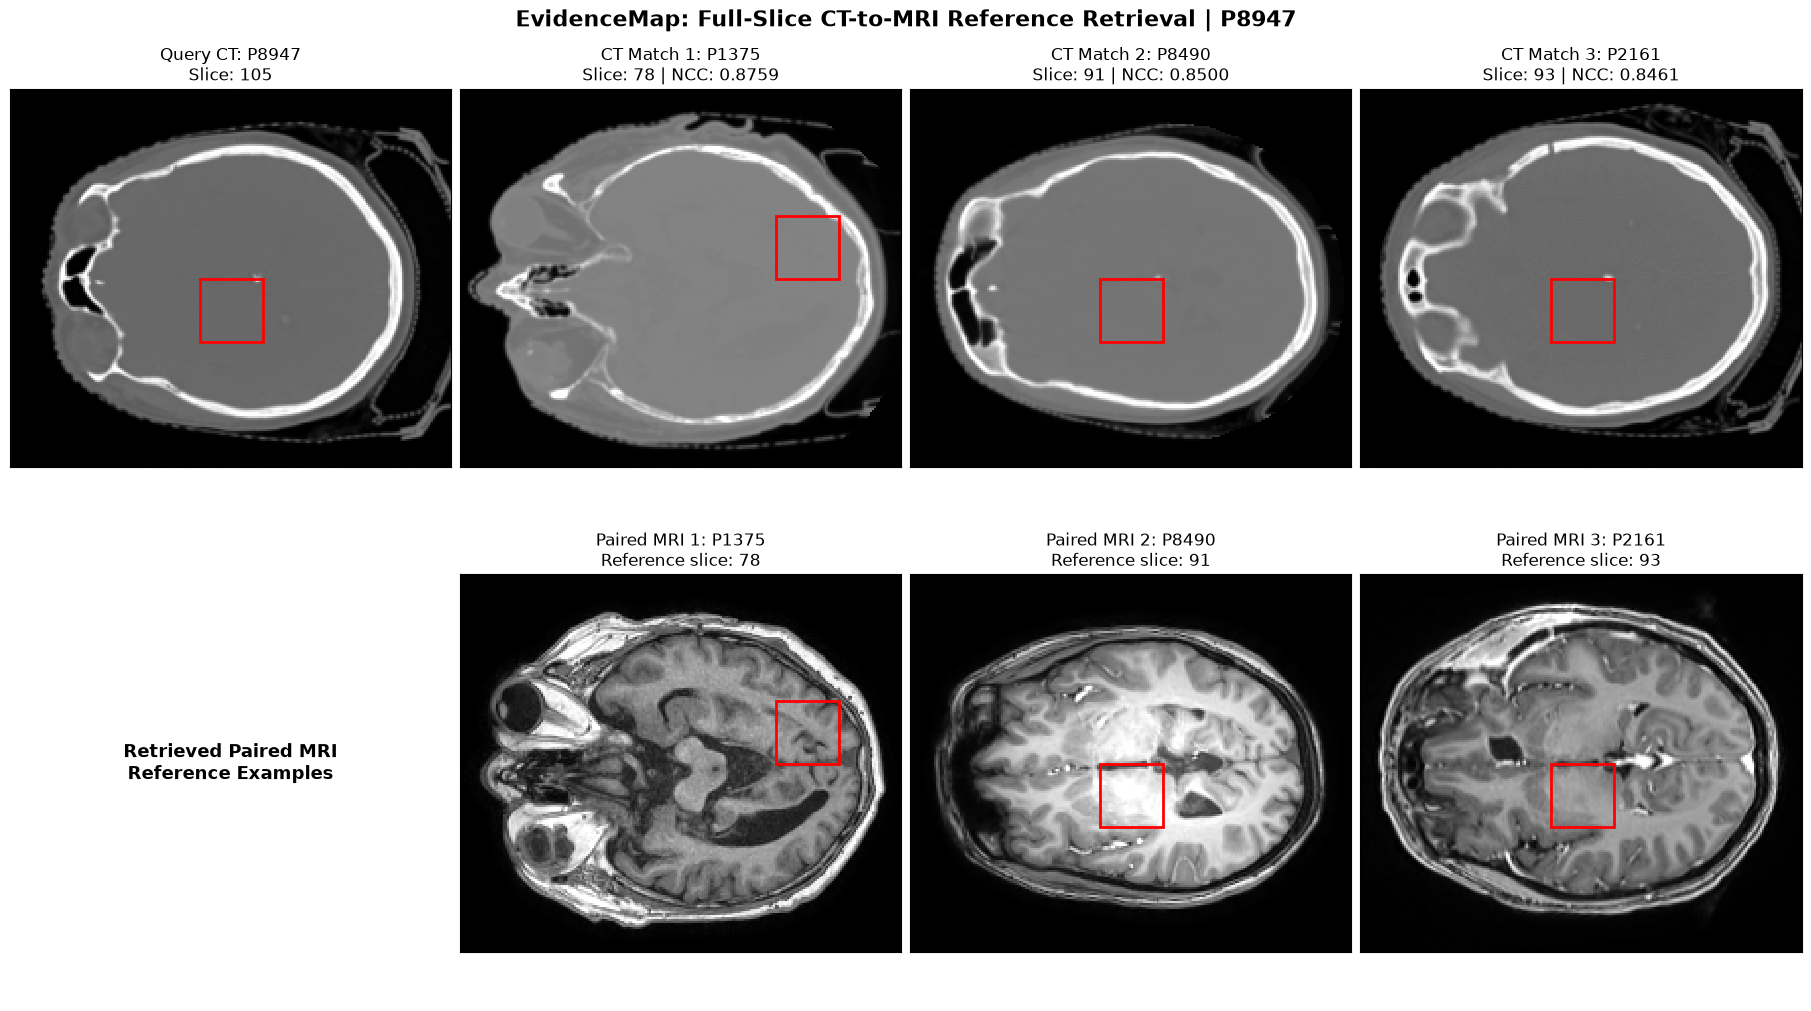


FULL-SLICE EVIDENCEMAP COMPLETED
Saved: D:\PS07_CT2MRI\outputs\evidence_map\P8947_evidence_map_full_slices.png


In [7]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


# ------------------------------------------------------------
# Load and normalize full patient volumes
# ------------------------------------------------------------

def load_patient_slices(patient_id, z):

    patient_dir = PROJECT_ROOT / "dataset" / "volumes" / patient_id

    ct_img = nib.load(str(patient_dir / "ct.nii.gz"))
    mr_img = nib.load(str(patient_dir / "mr.nii.gz"))
    mask_img = nib.load(str(patient_dir / "mask.nii.gz"))

    ct = ct_img.get_fdata(dtype=np.float32)
    mr = mr_img.get_fdata(dtype=np.float32)
    mask = mask_img.get_fdata(dtype=np.float32) > 0

    if not (ct.shape == mr.shape == mask.shape):
        raise ValueError(f"Volume shape mismatch: {patient_id}")

    if not (
        np.allclose(ct_img.affine, mr_img.affine)
        and np.allclose(ct_img.affine, mask_img.affine)
    ):
        raise ValueError(f"Affine mismatch: {patient_id}")

    # Official CT normalization
    ct = np.clip(ct, -1000.0, 2000.0)
    ct = (ct + 1000.0) / 3000.0

    # Official MRI normalization
    scale = np.percentile(mr[mask], 99.5)
    mr = np.clip(mr / max(float(scale), 1e-6), 0, 1)

    return ct[:, :, z], mr[:, :, z], mask[:, :, z]


# ------------------------------------------------------------
# Display contrast adjustment (visualization only)
# ------------------------------------------------------------

def improve_display(image, mask):

    values = image[mask]

    if len(values) == 0:
        values = image.ravel()

    low, high = np.percentile(values, [1, 99])

    if high <= low:
        return image

    return np.clip((image - low) / (high - low), 0, 1)


# ------------------------------------------------------------
# Draw patch location
# ------------------------------------------------------------

def draw_patch_box(ax, x, y, color="red"):

    # NIfTI array indexing:
    # first dimension = x (displayed vertically)
    # second dimension = y (displayed horizontally)
    ax.add_patch(
        Rectangle(
            (y, x),
            32,
            32,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )
    )


# ------------------------------------------------------------
# Create full-slice EvidenceMap
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 10),
    constrained_layout=True
)

fig.suptitle(
    f"EvidenceMap: Full-Slice CT-to-MRI Reference Retrieval | {PATIENT_ID}",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# Query patient full CT
# ------------------------------------------------------------

query_info = result["query_info"]

query_ct_full, _, query_mask = load_patient_slices(
    PATIENT_ID,
    query_info["slice_z"]
)

axes[0, 0].imshow(
    improve_display(query_ct_full, query_mask),
    cmap="gray",
    interpolation="nearest"
)

draw_patch_box(
    axes[0, 0],
    query_info["patch_x"],
    query_info["patch_y"]
)

axes[0, 0].set_title(
    f"Query CT: {PATIENT_ID}\n"
    f"Slice: {query_info['slice_z']}"
)


# ------------------------------------------------------------
# Retrieved full CT and paired MRI slices
# ------------------------------------------------------------

for i, match in enumerate(matches):

    source_id = match["patient_id"]
    source_z = match["z"]

    ct_slice, mr_slice, source_mask = load_patient_slices(
        source_id,
        source_z
    )

    # Full retrieved CT
    axes[0, i + 1].imshow(
        improve_display(ct_slice, source_mask),
        cmap="gray",
        interpolation="nearest"
    )

    draw_patch_box(
        axes[0, i + 1],
        match["x"],
        match["y"]
    )

    axes[0, i + 1].set_title(
        f"CT Match {i + 1}: {source_id}\n"
        f"Slice: {source_z} | "
        f"NCC: {match['similarity']:.4f}"
    )

    # Full paired MRI
    axes[1, i + 1].imshow(
        mr_slice,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    draw_patch_box(
        axes[1, i + 1],
        match["x"],
        match["y"]
    )

    axes[1, i + 1].set_title(
        f"Paired MRI {i + 1}: {source_id}\n"
        f"Reference slice: {source_z}"
    )


# ------------------------------------------------------------
# Label second row
# ------------------------------------------------------------

axes[1, 0].axis("off")

axes[1, 0].text(
    0.5,
    0.5,
    "Retrieved Paired MRI\nReference Examples",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)


# ------------------------------------------------------------
# Formatting and save
# ------------------------------------------------------------

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

OUTPUT_FILE = (
    OUTPUT_DIR / f"{PATIENT_ID}_evidence_map_full_slices.png"
)

fig.savefig(
    OUTPUT_FILE,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nFULL-SLICE EVIDENCEMAP COMPLETED")
print("Saved:", OUTPUT_FILE)
